In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
cols = ['symboling','normalized_losses','make','fuel_type','aspiration','num_doors',
        'body_style','drive_wheels','engine_location','wheel_base','length','width',
        'height','curb_weight','engine_type','num_cylinders','engine_size',
        'fuel_system','bore','stroke','compression_ratio','horsepower','peak_rpm',
        'city_mpg','highway_mpg','price']

In [9]:
df = pd.read_csv(r"C:\Users\Admin\Desktop\weekly task\Automobile_data.csv", names=cols)
df.replace('?', np.nan, inplace=True)

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9,111,5000,21,27,13495
2,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9,111,5000,21,27,16500
3,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9,154,5000,19,26,16500
4,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10,102,5500,24,30,13950
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
202,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
203,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
204,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.4,23,106,4800,26,27,22470


In [10]:
num_cols = ['normalized_losses','wheel_base','length','width','height','curb_weight',
            'bore','stroke','compression_ratio','horsepower','peak_rpm',
            'engine_size','city_mpg','highway_mpg','price']

In [11]:
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    # FIX for warning - use this style
    df[col] = df[col].fillna(df[col].median())

In [12]:
# Feature Engineering
df['power_to_weight'] = df['horsepower'] / df['curb_weight']
df['combined_mpg'] = (df['city_mpg'] + df['highway_mpg']) / 2

In [13]:
print("Cleaning done - No errors!")
print(df.head())

Cleaning done - No errors!
   symboling  normalized_losses         make  fuel_type  aspiration  \
0  symboling              115.0         make  fuel-type  aspiration   
1          3              115.0  alfa-romero        gas         std   
2          3              115.0  alfa-romero        gas         std   
3          1              115.0  alfa-romero        gas         std   
4          2              164.0         audi        gas         std   

      num_doors   body_style  drive_wheels  engine_location  wheel_base  ...  \
0  num-of-doors   body-style  drive-wheels  engine-location        97.0  ...   
1           two  convertible           rwd            front        88.6  ...   
2           two  convertible           rwd            front        88.6  ...   
3           two    hatchback           rwd            front        94.5  ...   
4          four        sedan           fwd            front        99.8  ...   

   bore  stroke  compression_ratio  horsepower peak_rpm city_mpg 

In [14]:
# 6. Statistical summaries
print(df.groupby('body_style')[['price','horsepower','combined_mpg']].describe())
print(df.groupby('engine_location')[['price']].mean())

            price                                                          \
            count          mean           std      min       25%      50%   
body_style                                                                  
body-style    1.0  10295.000000           NaN  10295.0  10295.00  10295.0   
convertible   6.0  21890.500000  11187.802193  11595.0  14246.25  17084.5   
hardtop       8.0  22208.500000  14555.520749   8249.0   9341.50  19687.5   
hatchback    70.0   9967.085714   4088.685922   5118.0   6564.00   8897.0   
sedan        96.0  14372.989583   8454.188110   5499.0   8042.25  10846.5   
wagon        25.0  12371.960000   5120.948695   6918.0   8013.00  11694.0   

                               horsepower              ...                 \
                  75%      max      count        mean  ...     75%    max   
body_style                                             ...                  
body-style   10295.00  10295.0        1.0   95.000000  ...   95.00   95.0  

In [15]:
sns.set_style("whitegrid")

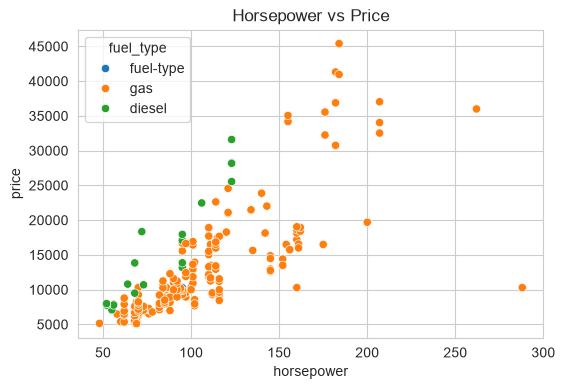

In [16]:
# 1. Scatter: Horsepower vs Price
plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x='horsepower', y='price', hue='fuel_type')
plt.title('Horsepower vs Price')
plt.show()

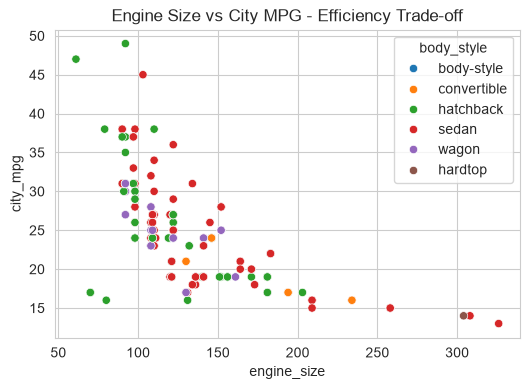

In [17]:
# 2. Scatter: Engine Size vs City MPG
plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x='engine_size', y='city_mpg', hue='body_style')
plt.title('Engine Size vs City MPG - Efficiency Trade-off')
plt.show()

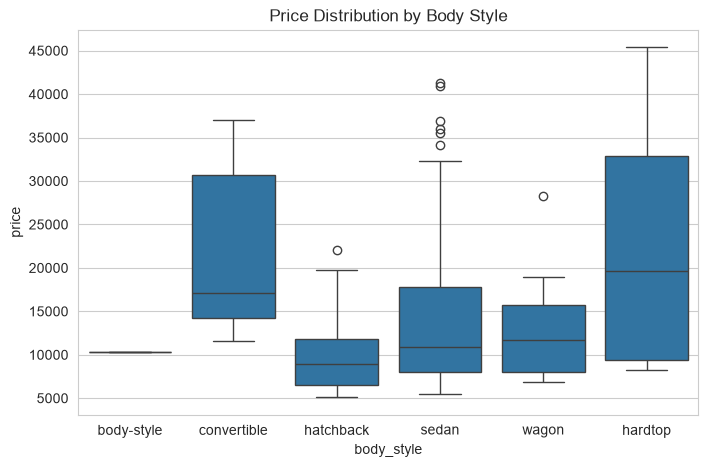

In [18]:
# 3. Boxplot: Price across body styles
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='body_style', y='price')
plt.title('Price Distribution by Body Style')
plt.show()

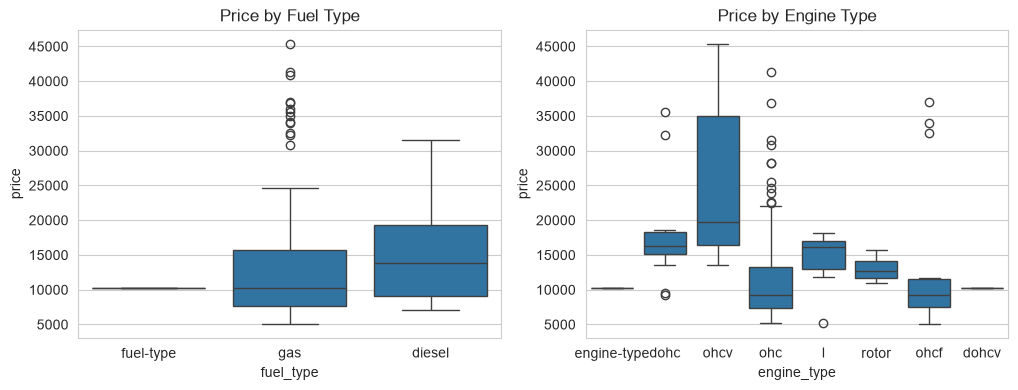

In [19]:
# 4. Boxplot: Price by fuel_type and engine_type
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.boxplot(data=df, x='fuel_type', y='price')
plt.title('Price by Fuel Type')

plt.subplot(1,2,2)
sns.boxplot(data=df, x='engine_type', y='price')
plt.title('Price by Engine Type')
plt.show()

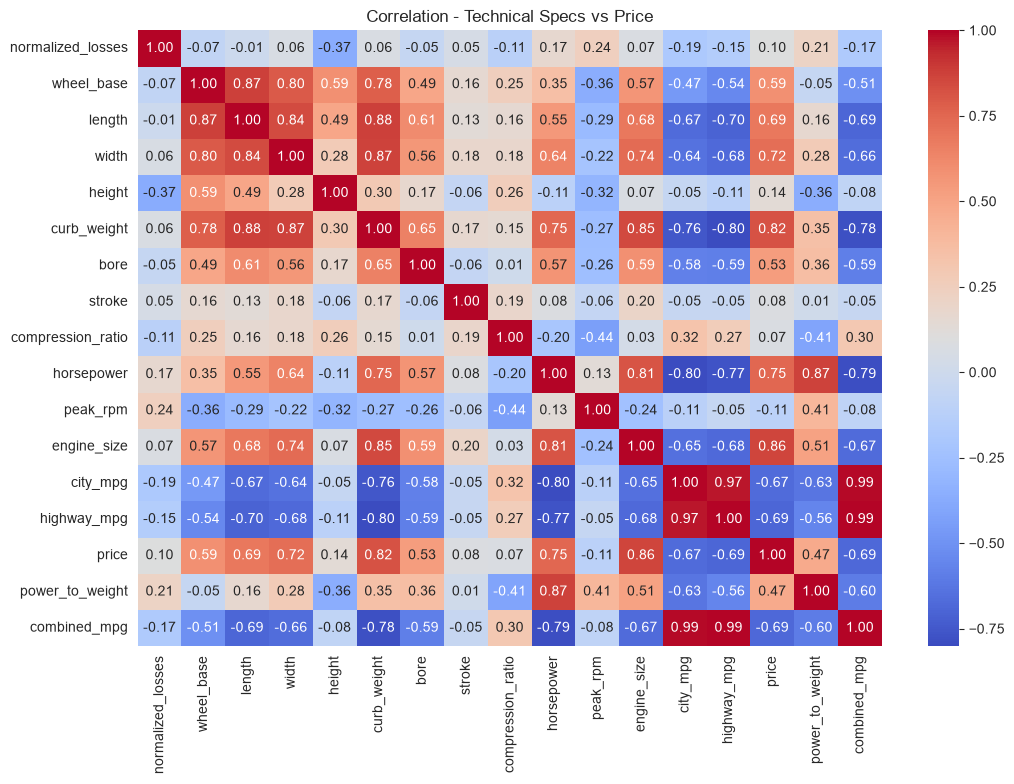

In [20]:
# 5. Correlation heatmap
plt.figure(figsize=(12,8))
corr = df[num_cols + ['power_to_weight','combined_mpg']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlation - Technical Specs vs Price')
plt.show()

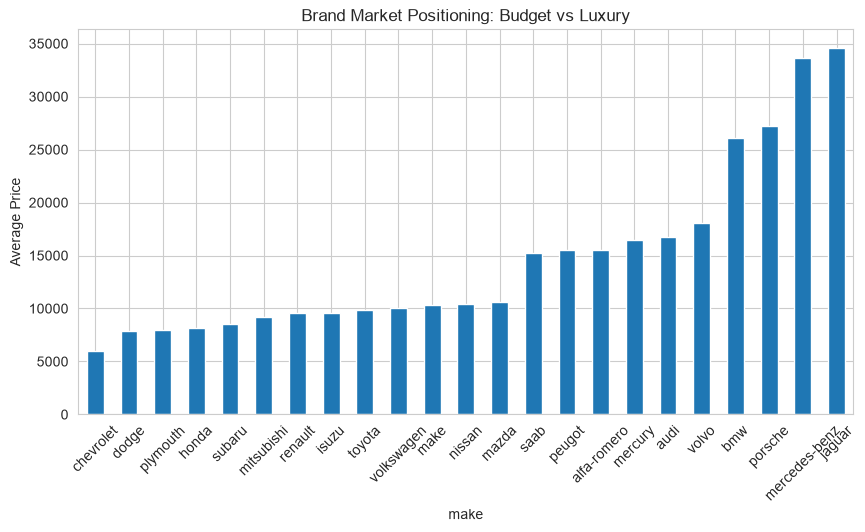

In [21]:
# 6. Brand positioning
plt.figure(figsize=(10,5))
brand_price = df.groupby('make')['price'].mean().sort_values()
brand_price.plot(kind='bar')
plt.title('Brand Market Positioning: Budget vs Luxury')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()

In [22]:
print("Competitive Report:")
print(f"Avg Price: {df['price'].mean():.0f}")
print(f"Highest power-to-weight: {df.loc[df['power_to_weight'].idxmax(), 'make']}")
print("Trade-off: Engine size ↑ Horsepower ↑ Price ↑ but MPG ↓")

Competitive Report:
Avg Price: 13136
Highest power-to-weight: porsche
Trade-off: Engine size ↑ Horsepower ↑ Price ↑ but MPG ↓


#### REPORT

#### This program performs data preprocessing and cleaning on an automobile dataset using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn. 

#### It begins by defining column names for the dataset and loading the automobile data from a CSV file into a DataFrame. Missing values represented by the symbol '?' are replaced with NaN to enable proper handling of incomplete data. 

#### A list of numerical columns is then identified, and each column is converted to a numeric data type using pd.to_numeric(), with invalid entries automatically converted to missing values.

#### To ensure data consistency and avoid errors during analysis, missing values in these numerical attributes are imputed using the median of their respective columns. 

#### This preprocessing step prepares the dataset for further exploratory data analysis, visualization, and machine learning tasks by creating a clean, structured, and reliable dataset